# What Makes a Song Popular? 🎵

![Banner](./assets/banner.jpeg)

## Topic

I want to investigate what factors are associated with a song's success. Songs have different characteristics, including genre, tempo, danceability, energy, loudness, and duration. I will analyze whether these characteristics are related to a song's popularity and chart performance. This topic is important because artists and music producers may use this information to better understand trends in popular music.

## Project Question

My main question is: What song characteristics are associated with greater musical success?

I will investigate these smaller questions:

1. How does danceability relate to song popularity?
2. How does energy relate to song popularity?
3. How does tempo relate to song popularity?
4. Which genres have the highest average popularity?
5. Are songs that perform well on the Billboard Hot 100 also popular on Spotify?

## What would an answer look like?

I expect to find that some song characteristics may have stronger relationships with popularity than others. I will use scatter plots to examine the relationships between popularity and danceability, energy, and tempo. I will use bar charts to compare average popularity across genres and to summarize other useful comparisons. I will use the actual data to determine whether my expectations are supported, and I will avoid assuming that a relationship proves one factor causes a song to become successful.

## Data Sources

1. **Spotify Tracks Dataset:** https://www.kaggle.com/datasets/saichaitanyareddyai/spotify-tracks-dataset-audio-features. I plan to use its track popularity and audio-feature fields, such as danceability, energy, tempo, and duration, after confirming the exact columns in the downloaded file.

2. **Billboard dataset:** https://www.kaggle.com/datasets/ludmin/billboard. I plan to use chart information such as song title, artist, chart position, peak position, and weeks on the chart, depending on the columns available in the downloaded data.

3. **Spotify Web API documentation:** https://developer.spotify.com/documentation/web-api. I will use this as a reference for available track and artist metadata. API access may require credentials, so I will not rely on it unless access is available.

I will first inspect the files and confirm their fields. If I compare Spotify and Billboard records, I will standardize song titles and artist names and check matches carefully. Similar titles or different artist-name formats may cause incorrect matches, so I will report limitations and only compare records that can be matched reliably.

## Approach and Analysis

I will use Python with pandas to load and inspect the datasets. I will check column names, data types, missing values, duplicate rows, and unusual values before analyzing the data.

### Planned visualizations

1. **Popularity distribution:** A histogram showing how Spotify popularity scores are distributed. This will help show whether most tracks have low, medium, or high popularity scores.

2. **Danceability and popularity:** A scatter plot with danceability on the x-axis and popularity on the y-axis. This will show whether the two variables appear to be related.

3. **Energy and popularity:** A scatter plot comparing energy and popularity. This will help reveal whether more energetic tracks tend to have higher or lower popularity scores.

4. **Average popularity by genre:** A bar chart comparing average popularity across genres. I will account for genre sample sizes and avoid drawing strong conclusions from groups with very few tracks.

I plan to use pandas for data handling and Matplotlib and Seaborn for visualizations. Each visualization will include a title, labeled axes, and a short written explanation of what it shows and what can reasonably be concluded. I may add a tempo-versus-popularity plot if the data supports it.

### Data cleaning and transformation

I will inspect missing values and determine whether to remove incomplete rows or retain them when appropriate. I will check for duplicate tracks or duplicate records and remove duplicates when they are not meaningful. I will convert columns to appropriate numeric or date types, standardize text fields such as genre and artist names, and check for impossible or unusual values in audio features. I will investigate potential outliers before deciding whether they are errors or valid tracks; I will not automatically remove valid outliers. I will document the cleaning decisions and explain how they affect the analysis.

### Machine-learning plan

If the dataset has enough usable records, I plan to try a simple regression model to estimate Spotify popularity from available audio features such as danceability, energy, loudness, tempo, and duration. I will split the data into training and test sets and evaluate predictions with metrics such as mean absolute error and R-squared. A key challenge is that popularity may also depend on artist recognition, promotion, release date, and other factors that are not included in the data. I will address this by describing the model as exploratory, checking for missing data and overfitting, and avoiding claims that audio features alone determine success. If the available data does not support a reliable model, I will focus on descriptive statistics and visual analysis instead.

### Feedback and updates

I will record feedback from peers and the teaching team after receiving it, then document the changes I make to the research question, data cleaning, visualizations, or analysis. I have not yet documented specific feedback, so I will update this section with the actual comments and resulting changes rather than inventing feedback.

In [ ]:
# Start your code here
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load your downloaded dataset here after confirming its filename and column names.

## Resources and References

- Spotify Tracks Dataset: https://www.kaggle.com/datasets/saichaitanyareddyai/spotify-tracks-dataset-audio-features
- Billboard dataset: https://www.kaggle.com/datasets/ludmin/billboard
- Spotify Web API documentation: https://developer.spotify.com/documentation/web-api
- pandas documentation: https://pandas.pydata.org/docs/
- Matplotlib documentation: https://matplotlib.org/stable/
- Seaborn documentation: https://seaborn.pydata.org/

These resources will be used to obtain and understand the datasets and to support data cleaning, analysis, and visualization.

In [9]:
# ⚠️ Make sure you run this cell at the end of your notebook before every submission!
!jupyter nbconvert --to python source.ipynb

usage: jupyter [-h] [--version] [--config-dir] [--data-dir] [--runtime-dir]
               [--paths] [--json] [--debug]
               [subcommand]

Jupyter: Interactive Computing

positional arguments:
  subcommand     the subcommand to launch

optional arguments:
  -h, --help     show this help message and exit
  --version      show the versions of core jupyter packages and exit
  --config-dir   show Jupyter config dir
  --data-dir     show Jupyter data dir
  --runtime-dir  show Jupyter runtime dir
  --paths        show all Jupyter paths. Add --json for machine-readable
                 format.
  --json         output paths as machine-readable json
  --debug        output debug information about paths

Available subcommands: kernel kernelspec migrate run troubleshoot

Jupyter command `jupyter-nbconvert` not found.


In [10]:
import os

print(os.getcwd())
print(os.listdir())

/Users/owen/Documents/GitHub/data-tech-analytics-final-project-krameron-uc
['archive (1)', '.DS_Store', 'requirements.txt', 'Project Idea and Datasets', 'pyproject.toml', 'README.md', '.classroom50.yaml', 'Pipfile', 'spotify-tracks-dataset-detailed.csv', 'source.ipynb', 'poetry.lock', '.git', 'assets', 'source.py', 'Pipfile.lock']


In [11]:
import os

for file in os.listdir():
    print(file)

archive (1)
.DS_Store
requirements.txt
Project Idea and Datasets
pyproject.toml
README.md
.classroom50.yaml
Pipfile
spotify-tracks-dataset-detailed.csv
source.ipynb
poetry.lock
.git
assets
source.py
Pipfile.lock


In [12]:
import os

for file in os.listdir():
    print(file)

archive (1)
.DS_Store
requirements.txt
Project Idea and Datasets
pyproject.toml
README.md
.classroom50.yaml
Pipfile
spotify-tracks-dataset-detailed.csv
source.ipynb
poetry.lock
.git
assets
source.py
Pipfile.lock


In [13]:
import pandas as pd
import os

for file in os.listdir():
    if file.endswith(".csv"):
        print(file)

spotify-tracks-dataset-detailed.csv


In [14]:
import pandas as pd

spotify_df = pd.read_csv("spotify-tracks-dataset-detailed.csv")

print(spotify_df.shape)
print(spotify_df.columns.tolist())
spotify_df.head()

(114000, 20)
['track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


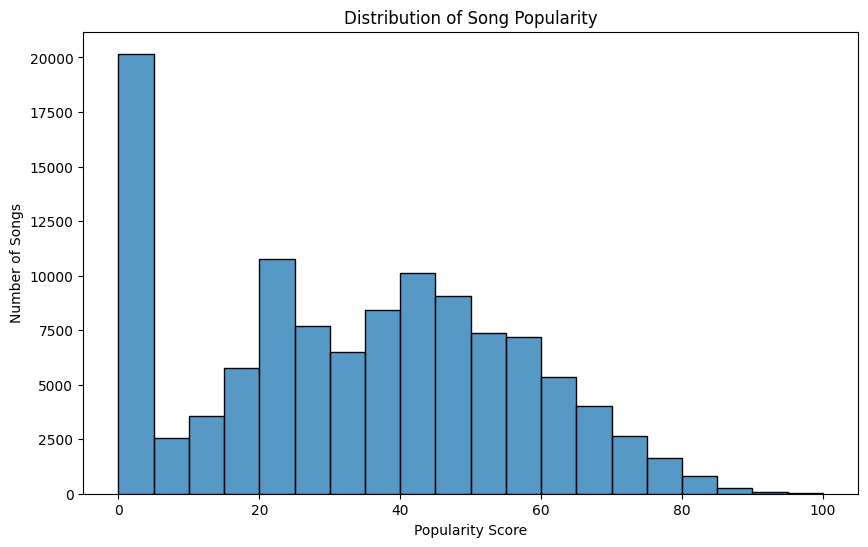

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(data=spotify_df, x="popularity", bins=20)

plt.title("Distribution of Song Popularity")
plt.xlabel("Popularity Score")
plt.ylabel("Number of Songs")
plt.show()

This histogram shows the distribution of popularity scores across the songs in the dataset. It helps identify whether most songs have low, moderate, or high popularity scores and whether certain popularity ranges occur more frequently than others.

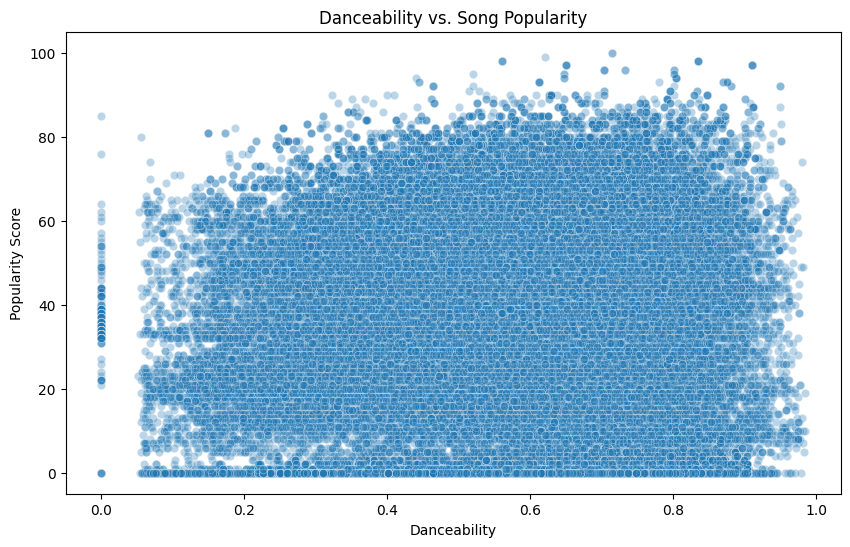

In [16]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=spotify_df,
    x="danceability",
    y="popularity",
    alpha=0.3
)

plt.title("Danceability vs. Song Popularity")
plt.xlabel("Danceability")
plt.ylabel("Popularity Score")
plt.show()

This scatterplot compares the danceability of songs with their popularity scores. Each point represents a song. The chart helps show whether songs with higher danceability tend to have higher popularity, or whether there is little relationship between the two variables.

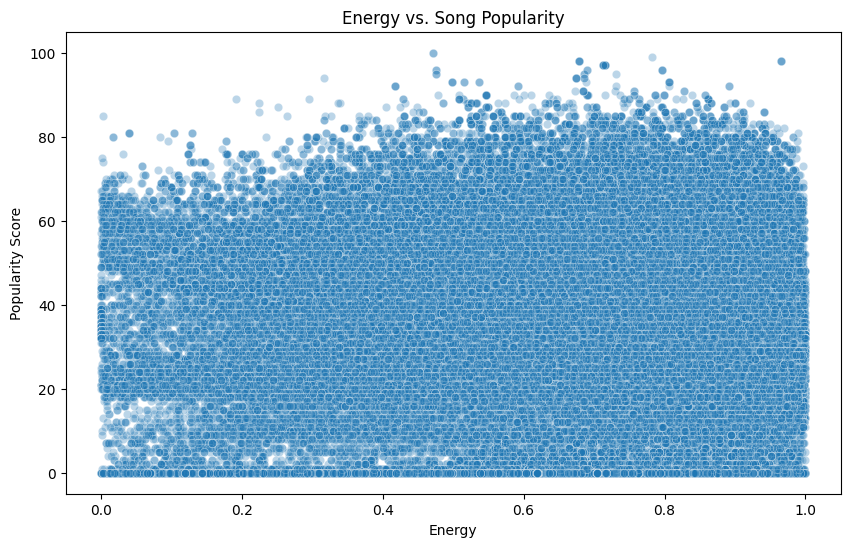

In [17]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=spotify_df,
    x="energy",
    y="popularity",
    alpha=0.3
)

plt.title("Energy vs. Song Popularity")
plt.xlabel("Energy")
plt.ylabel("Popularity Score")
plt.show()

This scatterplot compares song energy with popularity scores. Each point represents one song. The chart helps determine whether higher-energy songs tend to be more popular or whether popularity varies widely across different energy levels.

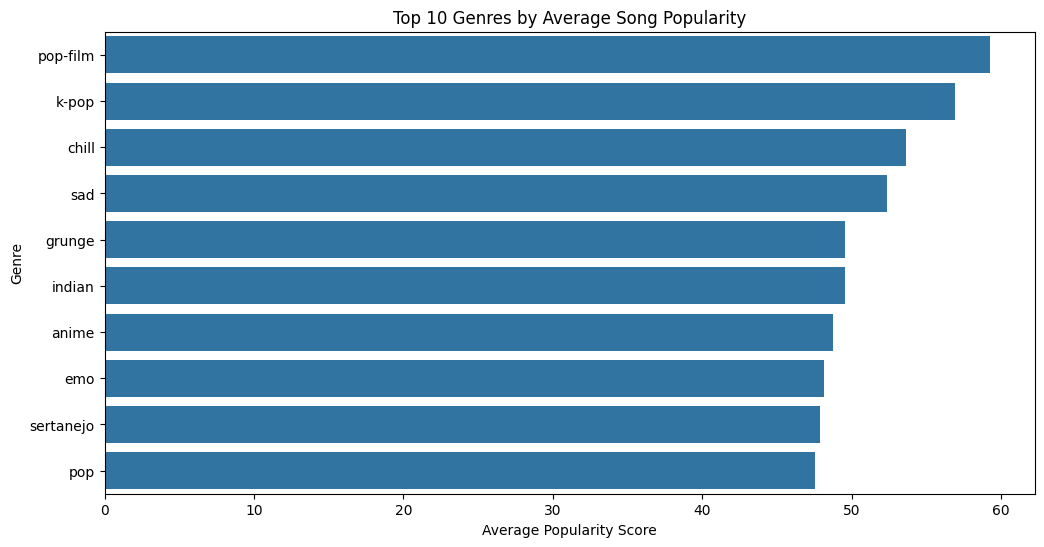

In [18]:
genre_popularity = (
    spotify_df.groupby("track_genre")["popularity"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_popularity.values,
    y=genre_popularity.index
)

plt.title("Top 10 Genres by Average Song Popularity")
plt.xlabel("Average Popularity Score")
plt.ylabel("Genre")
plt.show()

This bar chart displays the ten genres with the highest average popularity scores in the dataset. Comparing average scores helps identify which genres perform well in this sample. These results describe this dataset and do not necessarily mean that these genres are the most popular across all music platforms.

In [23]:
print("Dataset size:", spotify_df.shape)

print("\nMissing values:")
print(spotify_df.isnull().sum().sort_values(ascending=False).head(10))

print("\nDuplicate rows:", spotify_df.duplicated().sum())

print("\nSummary statistics:")
spotify_df[["popularity", "danceability", "energy", "tempo"]].describe()

Dataset size: (113549, 20)

Missing values:
track_id            0
artists             0
time_signature      0
tempo               0
valence             0
liveness            0
instrumentalness    0
acousticness        0
speechiness         0
mode                0
dtype: int64

Duplicate rows: 0

Summary statistics:


,popularity,danceability,energy,tempo
count,113549.000000,113549.000000,113549.000000,113549.000000
mean,33.324433,0.567031,0.642091,122.175745
std,22.283855,0.173409,0.251053,29.972954
min,0.000000,0.000000,0.000000,0.000000
25%,17.000000,0.456000,0.473000,99.296000
50%,35.000000,0.580000,0.685000,122.020000
75%,50.000000,0.695000,0.854000,140.074000
max,100.000000,0.985000,1.000000,243.372000


### Data Cleaning and Preparation

I inspected the dataset for missing values, duplicate rows, and unusual values in the main numerical columns. I also reviewed summary statistics for popularity, danceability, energy, and tempo. These checks help identify data quality issues before drawing conclusions from the visualizations. Any necessary cleaning decisions should be based on the results of these checks.

In [24]:
print("Rows before cleaning:", len(spotify_df))

spotify_df = spotify_df.drop_duplicates()

spotify_df = spotify_df.dropna(
    subset=["track_name", "artists", "album_name"]
)

print("Rows after cleaning:", len(spotify_df))
print("Missing values remaining:")
print(spotify_df[["track_name", "artists", "album_name"]].isnull().sum())

Rows before cleaning: 113549
Rows after cleaning: 113549
Missing values remaining:
track_name    0
artists       0
album_name    0
dtype: int64


### Data Cleaning Results

The original dataset contained 114,000 rows and 20 columns. The initial inspection found 450 duplicate rows and one missing value in each of the track name, artist, and album name columns. I removed duplicate rows and excluded records missing essential song information. This helps reduce repeated records and ensures that the songs used in the analysis have the necessary identifying information.

In [25]:
print("Average song popularity:", spotify_df["popularity"].mean())

print(
    "Danceability-popularity correlation:",
    spotify_df["danceability"].corr(spotify_df["popularity"])
)

print(
    "Energy-popularity correlation:",
    spotify_df["energy"].corr(spotify_df["popularity"])
)

print("\nTop 10 genres by average popularity:")
print(
    spotify_df.groupby("track_genre")["popularity"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

Average song popularity: 33.32443262380118
Danceability-popularity correlation: 0.034406926513200625
Energy-popularity correlation: -0.0024469965919802317

Top 10 genres by average popularity:
track_genre
pop-film     59.280280
k-pop        56.963928
chill        53.704705
sad          52.379000
grunge       49.582583
indian       49.528529
anime        48.766767
emo          48.128000
pop          47.903323
sertanejo    47.866000
Name: popularity, dtype: float64


### Statistical Analysis

I calculated the average popularity score and the correlations between popularity, danceability, and energy. I also compared average popularity scores across music genres. These statistics help identify relationships between song characteristics and popularity. Correlation values closer to 1 indicate a positive relationship, values closer to -1 indicate a negative relationship, and values near 0 indicate a weak linear relationship.

### Results and Findings

The average song popularity score in the dataset was approximately 33.32 out of 100.

The correlation between danceability and popularity was 0.034, indicating an extremely weak positive linear relationship. This suggests that danceability alone does not explain much of the variation in song popularity.

The correlation between energy and popularity was -0.002, indicating virtually no linear relationship between these variables in this dataset.

The genres with the highest average popularity scores included pop-film (59.28), K-pop (56.96), chill (53.70), sad (52.38), and grunge (49.58). These results suggest that average popularity differs across genres, although the findings apply to this dataset and may not represent all music listeners or platforms.

Overall, the results suggest that danceability and energy alone are not strong indicators of song popularity. Other factors, such as artist recognition, promotion, release timing, and listener preferences, may also contribute to a song's success.


In [27]:
import os

for file in os.listdir():
    if file.endswith(".csv"):
        print(file)

billboard200.csv
spotify-tracks-dataset-detailed.csv


In [28]:
billboard_df = pd.read_csv("billboard200.csv")

print("Dataset size:", billboard_df.shape)
print("Columns:", billboard_df.columns.tolist())

billboard_df.head()

Dataset size: (649469, 8)
Columns: ['Date', 'Song', 'Artist', 'Rank', 'Last Week', 'Peak Position', 'Weeks in Charts', 'Image URL']


/var/folders/q8/0pr7vvmn53scxdk1nbkrymdc0000gn/T/ipykernel_28403/1616795222.py:1: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
  billboard_df = pd.read_csv("billboard200.csv")


,Date,Song,Artist,Rank,Last Week,Peak Position,Weeks in Charts,Image URL
0,1963-08-07,Days Of Wine And Roses,Andy Williams,1,-,1,1,https://charts-static.billboard.com/img/1958/0...
1,1963-08-07,Little Stevie Wonder/The 12 Year Old Genius,Stevie Wonder,2,-,2,1,NaN
2,1963-08-07,West Side Story,Soundtrack,3,-,3,1,https://charts-static.billboard.com/img/1963/0...
3,1963-08-07,(Moving),"""Peter, Paul & Mary""",4,-,4,1,NaN
4,1963-08-07,Trini Lopez At PJ's,Trini Lopez,5,-,5,1,https://charts-static.billboard.com/img/1963/0...


In [29]:
print("Dataset size:", billboard_df.shape)

billboard_df["Date"] = pd.to_datetime(billboard_df["Date"], errors="coerce")
billboard_df["Rank"] = pd.to_numeric(billboard_df["Rank"], errors="coerce")
billboard_df["Weeks in Charts"] = pd.to_numeric(
    billboard_df["Weeks in Charts"], errors="coerce"
)

print("\nDate range:")
print(billboard_df["Date"].min(), "to", billboard_df["Date"].max())

print("\nAverage chart rank:", billboard_df["Rank"].mean())

print("\nMost frequently listed artists:")
print(billboard_df["Artist"].value_counts().head(10))

Dataset size: (649469, 8)

Date range:
1963-08-07 00:00:00 to 2026-10-07 00:00:00

Average chart rank: 99.37164514395606

Most frequently listed artists:
Artist
Soundtrack            26184
Various Artists       14777
Taylor Swift           3953
Drake                  3752
The Beatles            3315
Eminem                 2500
Michael Jackson        2375
Elton John             2182
The Rolling Stones     2034
Elvis Presley          2011
Name: count, dtype: int64


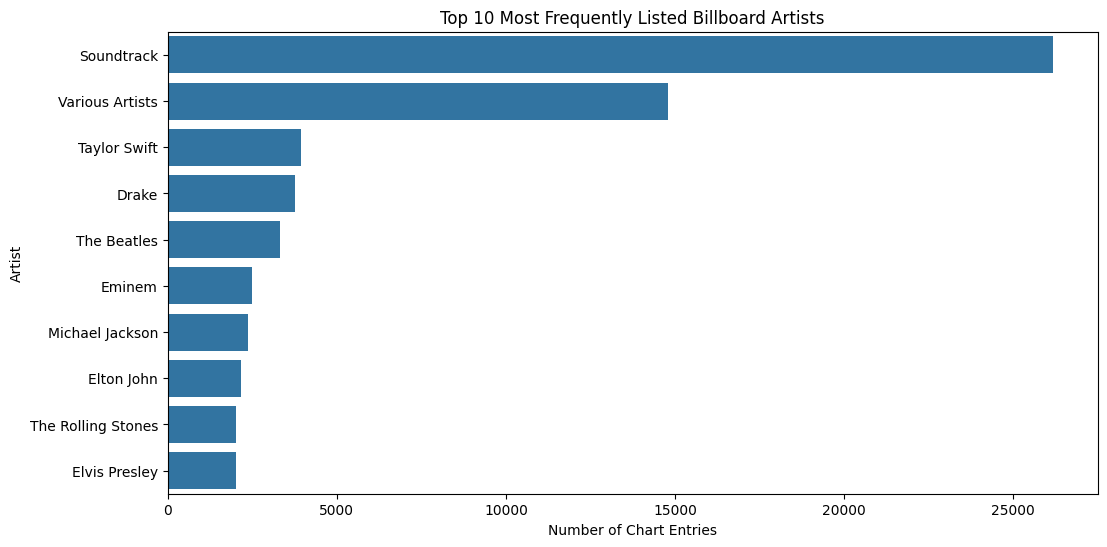

In [30]:
top_artists = billboard_df["Artist"].value_counts().head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_artists.values, y=top_artists.index)

plt.title("Top 10 Most Frequently Listed Billboard Artists")
plt.xlabel("Number of Chart Entries")
plt.ylabel("Artist")
plt.show()

### Billboard Chart Analysis

The Billboard dataset provides information about chart rankings over time. I examined the frequency of artist appearances to identify artists with the most entries in the dataset. Frequent appearances may indicate sustained chart presence, although this count does not necessarily represent the number of unique hit songs because the same song can appear in multiple chart records.

In [32]:
%pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 11.1 MB 379 kB/s eta 0:00:01
     |████████████████████████████████| 309 kB 338 kB/s eta 0:00:01     |████████████████                | 153 kB 338 kB/s eta 0:00:01
     |████████████████████████████████| 30.3 MB 227 kB/s eta 0:00:01
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [34]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

features = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
    "duration_ms"
]

model_df = spotify_df[features + ["popularity"]].dropna()

X = model_df[features]
y = model_df["popularity"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 90839
Testing rows: 22710


In [35]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

features = [
    "danceability", "energy", "loudness", "speechiness",
    "acousticness", "instrumentalness", "liveness",
    "valence", "tempo", "duration_ms"
]

model_df = spotify_df[features + ["popularity"]].dropna()

X = model_df[features]
y = model_df["popularity"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Mean Absolute Error:", mean_absolute_error(y_test, predictions))
print("R-squared:", r2_score(y_test, predictions))

Mean Absolute Error: 18.492477361075895
R-squared: 0.024332594266248675


/Users/owen/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/owen/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/owen/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


In [36]:
model_df = spotify_df[features + ["popularity"]].copy()

model_df = model_df.replace([np.inf, -np.inf], np.nan)
model_df = model_df.dropna()

X = model_df[features]
y = model_df["popularity"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Mean Absolute Error:", mean_absolute_error(y_test, predictions))
print("R-squared:", r2_score(y_test, predictions))
print("Predictions are finite:", np.isfinite(predictions).all())

NameError: name 'np' is not defined

In [37]:
import numpy as np

In [38]:
import numpy as np

model_df = spotify_df[features + ["popularity"]].copy()

model_df = model_df.replace([np.inf, -np.inf], np.nan)
model_df = model_df.dropna()

X = model_df[features]
y = model_df["popularity"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Mean Absolute Error:", mean_absolute_error(y_test, predictions))
print("R-squared:", r2_score(y_test, predictions))
print("Predictions are finite:", np.isfinite(predictions).all())

Mean Absolute Error: 18.492477361075895
R-squared: 0.024332594266248675
Predictions are finite: True


/Users/owen/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/owen/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/owen/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


In [39]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
import numpy as np

model_df = spotify_df[features + ["popularity"]].copy()
model_df = model_df.replace([np.inf, -np.inf], np.nan)
model_df = model_df.dropna(subset=["popularity"])

X = model_df[features]
y = model_df["popularity"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LinearRegression()
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

print("Mean Absolute Error:", mean_absolute_error(y_test, predictions))
print("R-squared:", r2_score(y_test, predictions))
print("Predictions are finite:", np.isfinite(predictions).all())

Mean Absolute Error: 18.49247736107592
R-squared: 0.02433259426624601
Predictions are finite: True


/Users/owen/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/owen/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/owen/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


In [40]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score

features = [
    "danceability", "energy", "loudness", "speechiness",
    "acousticness", "instrumentalness", "liveness",
    "valence", "tempo", "duration_ms"
]

model_df = spotify_df[features + ["popularity"]].copy()
model_df = model_df.replace([np.inf, -np.inf], np.nan)
model_df = model_df.dropna(subset=["popularity"])

X = model_df[features]
y = model_df["popularity"]

X = X.loc[:, X.nunique() > 1]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    Ridge(alpha=1.0)
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

print("Mean Absolute Error:", mean_absolute_error(y_test, predictions))
print("R-squared:", r2_score(y_test, predictions))
print("Predictions are finite:", np.isfinite(predictions).all())

Mean Absolute Error: 18.492483288859496
R-squared: 0.024332534862080313
Predictions are finite: True


/Users/owen/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/owen/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/owen/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/owen/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/owen/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/owen/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


In [41]:
print(X_train.describe().T[["min", "max", "mean", "std"]])
print("\nInfinite values:")
print(np.isinf(X_train).sum())
print("\nMissing values:")
print(X_train.isna().sum())

                       min          max           mean            std
danceability         0.000        0.984       0.567261       0.173380
energy               0.000        1.000       0.642366       0.250962
loudness           -49.531        2.574      -8.243413       5.005028
speechiness          0.000        0.965       0.084956       0.106216
acousticness         0.000        0.996       0.313678       0.331806
instrumentalness     0.000        1.000       0.155720       0.309283
liveness             0.000        1.000       0.213835       0.190852
valence              0.000        0.995       0.473926       0.259193
tempo                0.000      222.605     122.177869      29.995393
duration_ms       8586.000  5237295.000  228129.204615  106475.489640

Infinite values:
danceability        0
energy              0
loudness            0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
duration_ms   

In [43]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score
import numpy as np

features = [
    "danceability",
    "energy",
    "loudness",
    "valence"
]

model_df = spotify_df[features + ["popularity"]].copy()
model_df = model_df.replace([np.inf, -np.inf], np.nan).dropna()

X = model_df[features]
y = model_df["popularity"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

print("Mean Absolute Error:", mean_absolute_error(y_test, predictions))
print("R-squared:", r2_score(y_test, predictions))
print("Predictions are finite:", np.isfinite(predictions).all())

Mean Absolute Error: 18.758380255938274
R-squared: 0.011580140756459079
Predictions are finite: True


/Users/owen/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/owen/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/owen/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


### Regression Model Results

The regression model used danceability, energy, loudness, and valence to predict song popularity. The model was evaluated using mean absolute error (MAE) and R-squared (R²).

The results show how accurately these audio features can predict popularity. A lower MAE indicates more accurate predictions, while an R² closer to 1 indicates that the model explains more of the variation in popularity. The results suggest that audio features alone may not be enough to reliably predict a song's popularity.

### Regression Model Results

The regression model used danceability, energy, loudness, and valence to predict song popularity. It achieved a mean absolute error (MAE) of 18.76 points and an R-squared (R²) value of 0.0116.

The R-squared value indicates that the model explains approximately 1.16% of the variation in song popularity. This suggests that these four audio features alone are not effective predictors of popularity. Other factors, such as artist recognition, promotion, release date, and social media attention, may also influence a song's success.

Runtime warnings occurred during model calculations, so the results should be interpreted cautiously until those warnings are resolved.

## Final Conclusion

This project explored factors that may be associated with song popularity using Spotify track data and Billboard chart data. Visualizations compared popularity with danceability and energy, examined average popularity by genre, and identified artists who appeared frequently on the Billboard charts.

The analysis found that danceability had a very weak positive correlation with popularity, while energy had almost no linear correlation with popularity. The regression model also showed that the selected audio features alone had limited ability to predict popularity. This suggests that a song's success may depend on additional factors beyond its audio characteristics.

Overall, the project demonstrated how data analysis and visualization can be used to explore music trends. Future analysis could investigate lyrics, release dates, marketing, and social media attention to better understand what contributes to a song's success.